In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score)
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [2]:
df = pd.read_csv("w.csv")

In [3]:
print(df.shape)
print(df.head())
print(df.columns.tolist())
print(df.info())

(440, 8)
   Channel  Region  Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0        2       3  12669  9656     7561     214              2674        1338
1        2       3   7057  9810     9568    1762              3293        1776
2        2       3   6353  8808     7684    2405              3516        7844
3        1       3  13265  1196     4221    6404               507        1788
4        2       3  22615  5410     7198    3915              1777        5185
['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5  

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# Remove duplicate records if any
df = df.drop_duplicates().copy()

# Fill missing numeric values with the median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing Values After Treatment:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)

Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate Records: 0

Missing Values After Treatment:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Dataset Shape After Cleaning: (440, 8)


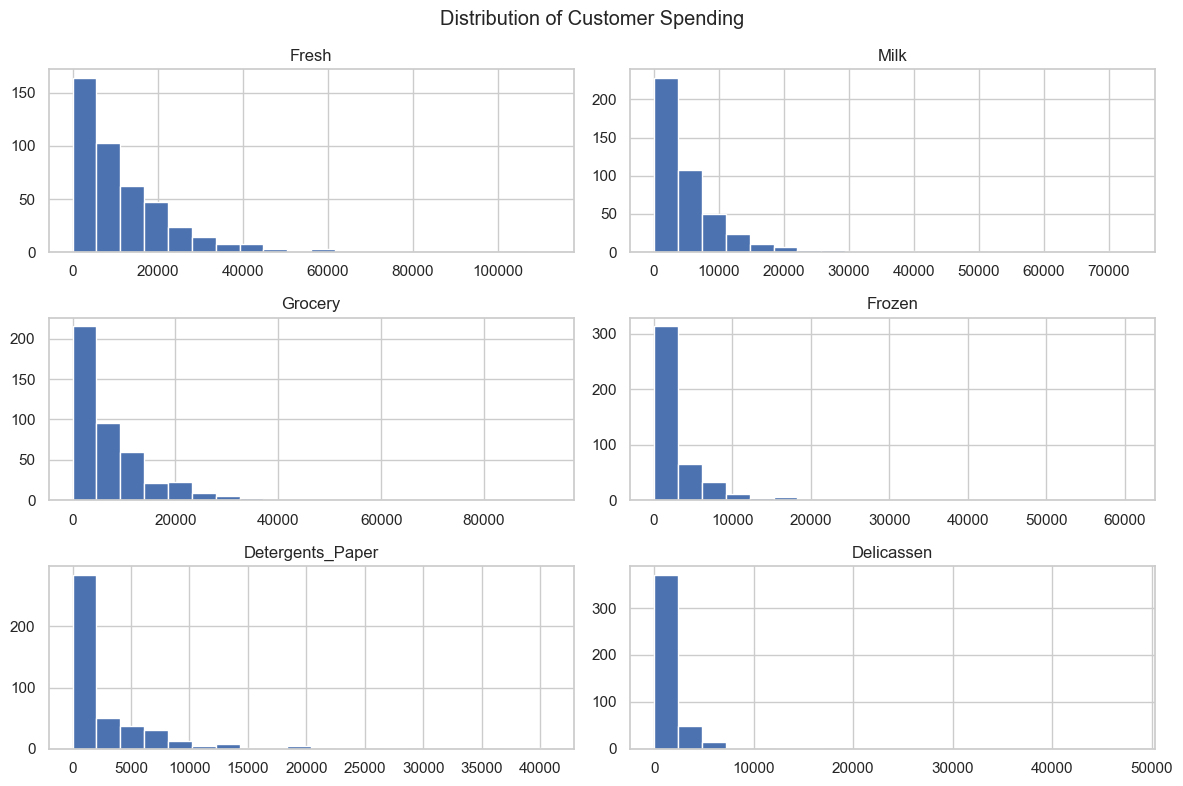

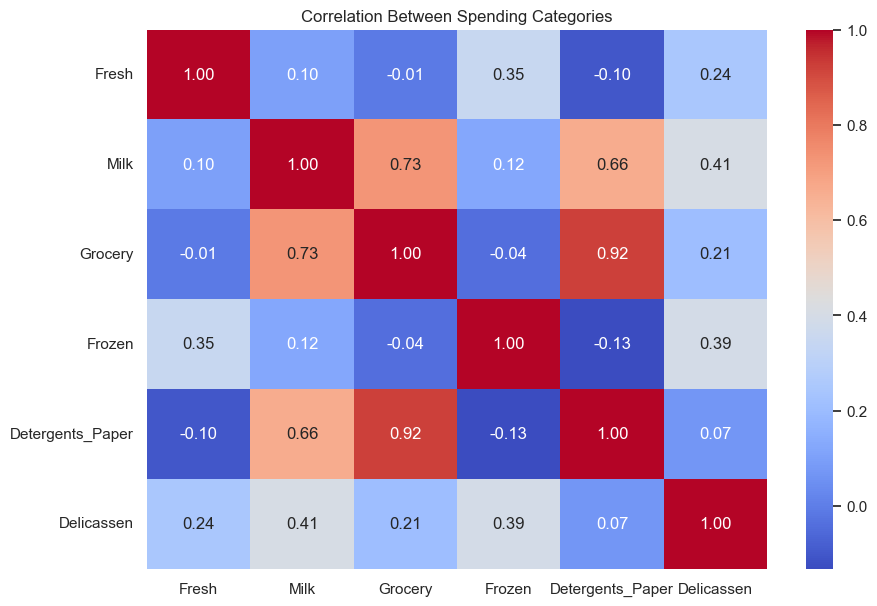

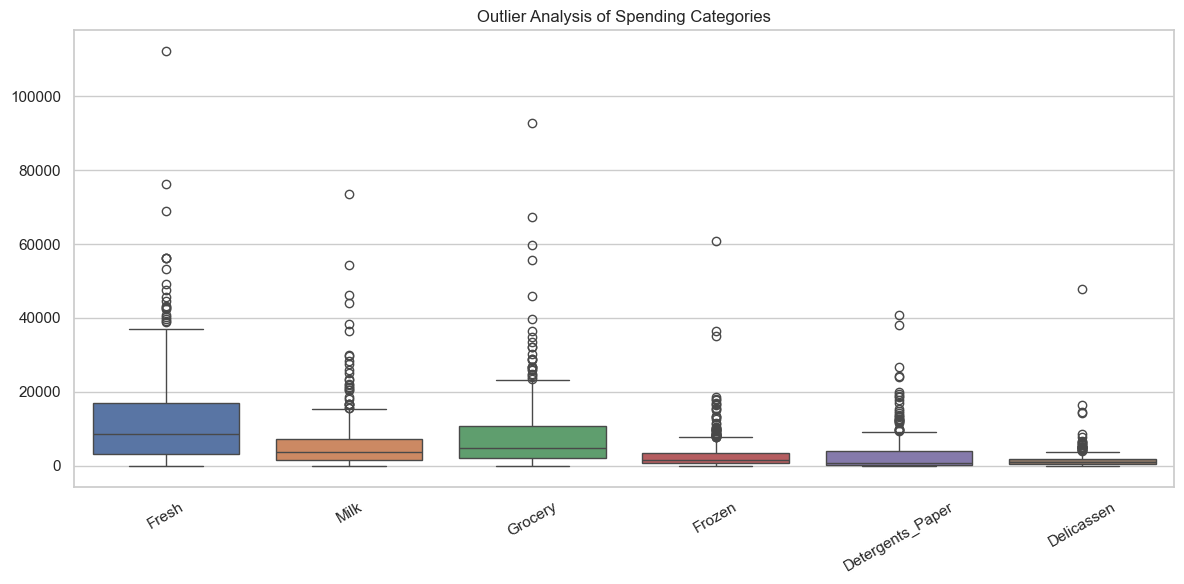

In [5]:
features = [
    'Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper', 'Delicassen'
]

# Histograms
df[features].hist(figsize=(12, 8), bins=20)
plt.suptitle("Distribution of Customer Spending")
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Spending Categories")
plt.show()

# Boxplots for detecting potential outliers
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[features])
plt.title("Outlier Analysis of Spending Categories")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [6]:
X = df[features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Data Shape:", X_scaled.shape)
print("\nFirst 5 Scaled Records:")
print(pd.DataFrame(
    X_scaled,
    columns=features
).head().round(2))

Scaled Data Shape: (440, 6)

First 5 Scaled Records:
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0   0.05  0.52    -0.04   -0.59             -0.04       -0.07
1  -0.39  0.54     0.17   -0.27              0.09        0.09
2  -0.45  0.41    -0.03   -0.14              0.13        2.24
3   0.10 -0.62    -0.39    0.69             -0.50        0.09
4   0.84 -0.05    -0.08    0.17             -0.23        1.30


  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.

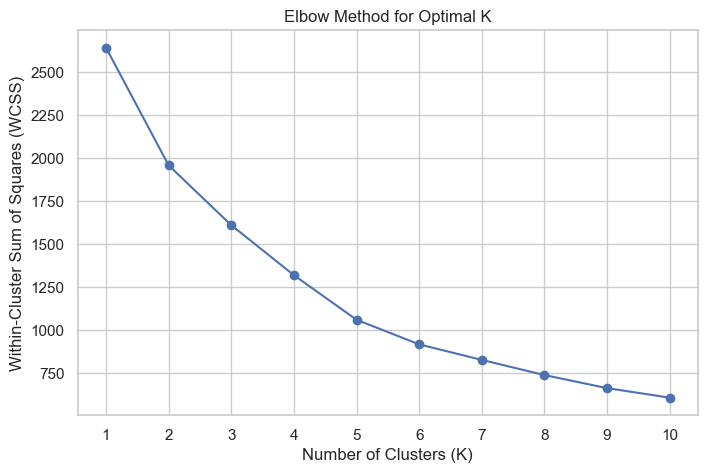

In [7]:
wcss = []

for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("Elbow Method for Optimal K")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [8]:
## kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Cluster Counts:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nAverage Spending by K-Means Cluster:")
print(
    df.groupby('KMeans_Cluster')[features]
      .mean()
      .round(2)
)

IndentationError: unexpected indent (1272585741.py, line 2)

In [ ]:
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_scaled)

print("Hierarchical Cluster Counts:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

print("\nAverage Spending by Hierarchical Cluster:")
print(
    df.groupby('Hierarchical_Cluster')[features]
      .mean()
      .round(2)
)

In [ ]:
linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=9
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer Groups")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    'PC1': X_pca[:, 0],
    'PC2': X_pca[:, 1],
    'KMeans_Cluster': df['KMeans_Cluster'],
    'Hierarchical_Cluster': df['Hierarchical_Cluster']
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=plot_df,
    x='PC1', y='PC2',
    hue='KMeans_Cluster',
    palette='Set1',
    ax=axes[0]
)
axes[0].set_title("K-Means Customer Segments")

sns.scatterplot(
    data=plot_df,
    x='PC1', y='PC2',
    hue='Hierarchical_Cluster',
    palette='Set2',
    ax=axes[1]
)
axes[1].set_title("Hierarchical Customer Segments")

plt.tight_layout()
plt.show()

print(
    "Variance explained by first 2 PCs:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical'],
    'Silhouette Score': [
        silhouette_score(X_scaled, df['KMeans_Cluster']),
        silhouette_score(X_scaled, df['Hierarchical_Cluster'])
    ],
    'Davies-Bouldin Index': [
        davies_bouldin_score(X_scaled, df['KMeans_Cluster']),
        davies_bouldin_score(X_scaled, df['Hierarchical_Cluster'])
    ]
})

print(comparison.round(3))

comparison.set_index('Algorithm').plot(
    kind='bar',
    figsize=(9, 5),
    subplots=True,
    layout=(1, 2),
    legend=False,
    rot=0
)

plt.tight_layout()
plt.show()